In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import os
import glob
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path

PROJECT_DIR = Path(
    r"D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised"
)

TEMPERATURE_DIR = PROJECT_DIR / "data" / "raw" / "temperature"
INTERMEDIATE_DIR = PROJECT_DIR / "data" / "intermediate"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
SPATIAL_DIR = PROJECT_DIR / "data" / "spatial"

print("Temperature directory:", TEMPERATURE_DIR)
print("Directory exists:", TEMPERATURE_DIR.exists())

Temperature directory: D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\data\raw\temperature
Directory exists: True


In [3]:
temperature_files = sorted(TEMPERATURE_DIR.iterdir())

print("Total files:", len(temperature_files))

for file_path in temperature_files:
    if file_path.is_file():
        print(file_path.name, "|", round(file_path.stat().st_size / (1024**2), 3), "MB")

Total files: 26
Maxtemp_MaxT_2000.nc | 1.353 MB
Maxtemp_MaxT_2001.nc | 1.35 MB
Maxtemp_MaxT_2002.nc | 1.35 MB
Maxtemp_MaxT_2003.nc | 1.35 MB
Maxtemp_MaxT_2004.nc | 1.353 MB
Maxtemp_MaxT_2005.nc | 1.35 MB
Maxtemp_MaxT_2006.nc | 1.35 MB
Maxtemp_MaxT_2007.nc | 1.35 MB
Maxtemp_MaxT_2008.nc | 1.353 MB
Maxtemp_MaxT_2009.nc | 1.35 MB
Maxtemp_MaxT_2010.nc | 1.35 MB
Maxtemp_MaxT_2011.nc | 1.35 MB
Maxtemp_MaxT_2012.nc | 1.353 MB
Maxtemp_MaxT_2013.nc | 1.35 MB
Maxtemp_MaxT_2014.nc | 1.35 MB
Maxtemp_MaxT_2015.nc | 1.35 MB
Maxtemp_MaxT_2016.nc | 1.353 MB
Maxtemp_MaxT_2017.nc | 1.35 MB
Maxtemp_MaxT_2018.nc | 1.35 MB
Maxtemp_MaxT_2019.nc | 1.35 MB
Maxtemp_MaxT_2020.nc | 1.353 MB
Maxtemp_MaxT_2021.nc | 1.35 MB
Maxtemp_MaxT_2022.nc | 1.35 MB
Maxtemp_MaxT_2023.nc | 1.35 MB
Maxtemp_MaxT_2024.GRD | 1.342 MB
Maxtemp_MaxT_2025.GRD | 1.338 MB


In [4]:
file_2000 = TEMPERATURE_DIR / "Maxtemp_MaxT_2000.nc"

with xr.open_dataset(file_2000) as ds:
    print(ds)
    print("\nGlobal attributes:")
    print(ds.attrs)

    print("\nTemperature variable attributes:")
    print(ds["temperature"].attrs)

    print("\nTime encoding:")
    print(ds["time"].encoding)

<xarray.Dataset> Size: 1MB
Dimensions:      (time: 366, lat: 31, lon: 31)
Coordinates:
  * time         (time) datetime64[ns] 3kB 2023-01-01 2023-01-02 ... 2024-01-01
  * lat          (lat) float64 248B 7.5 8.5 9.5 10.5 ... 34.5 35.5 36.5 37.5
  * lon          (lon) float64 248B 67.5 68.5 69.5 70.5 ... 94.5 95.5 96.5 97.5
Data variables:
    temperature  (time, lat, lon) float32 1MB ...
Attributes:
    description:  IMD 1°x1° Maximum Temperature Data from Maxtemp_MaxT_2000.GRD
    units:        °C

Global attributes:
{'description': 'IMD 1°x1° Maximum Temperature Data from Maxtemp_MaxT_2000.GRD', 'units': '°C'}

Temperature variable attributes:
{}

Time encoding:
{'dtype': dtype('int64'), 'zlib': False, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': False, 'complevel': 0, 'fletcher32': False, 'contiguous': True, 'chunksizes': None, 'source': 'D:\\SVKM NMIMS Indore\\Academic Related\\Research Papers\\Spatiotemporal GNN\\New Code Setup\\Spatiotemporal_GNN_Revise

In [5]:
netcdf_files = sorted(TEMPERATURE_DIR.glob("*.nc"))

temperature_inventory = []

for file_path in netcdf_files:

    with xr.open_dataset(file_path) as ds:

        year = int(file_path.stem.split("_")[-1])
        time_values = pd.to_datetime(ds["time"].values)

        temperature_inventory.append({
            "year_in_filename": year,
            "observations": ds.sizes["time"],
            "latitude_count": ds.sizes["lat"],
            "longitude_count": ds.sizes["lon"],
            "time_start": time_values[0],
            "time_end": time_values[-1],
            "units": ds.attrs.get("units")
        })

temperature_inventory_df = pd.DataFrame(temperature_inventory)

temperature_inventory_df

,year_in_filename,observations,latitude_count,longitude_count,time_start,time_end,units
0,2000,366,31,31,2023-01-01,2024-01-01,°C
1,2001,365,31,31,2023-01-01,2023-12-31,°C
2,2002,365,31,31,2023-01-01,2023-12-31,°C
3,2003,365,31,31,2023-01-01,2023-12-31,°C
4,2004,366,31,31,2023-01-01,2024-01-01,°C
5,2005,365,31,31,2023-01-01,2023-12-31,°C
6,2006,365,31,31,2023-01-01,2023-12-31,°C
7,2007,365,31,31,2023-01-01,2023-12-31,°C
8,2008,366,31,31,2023-01-01,2024-01-01,°C
9,2009,365,31,31,2023-01-01,2023-12-31,°C


In [6]:
reference_file = TEMPERATURE_DIR / "Maxtemp_MaxT_2000.nc"

with xr.open_dataset(reference_file) as ds:
    reference_lat = ds["lat"].values.copy()
    reference_lon = ds["lon"].values.copy()

coordinate_results = []

for file_path in netcdf_files:

    with xr.open_dataset(file_path) as ds:

        coordinate_results.append({
            "file": file_path.name,
            "latitude_match": np.array_equal(
                ds["lat"].values, reference_lat
            ),
            "longitude_match": np.array_equal(
                ds["lon"].values, reference_lon
            )
        })

coordinate_df = pd.DataFrame(coordinate_results)

print(coordinate_df.to_string(index=False))
print("\nAll latitude arrays match:",
      coordinate_df["latitude_match"].all())
print("All longitude arrays match:",
      coordinate_df["longitude_match"].all())


                file  latitude_match  longitude_match
Maxtemp_MaxT_2000.nc            True             True
Maxtemp_MaxT_2001.nc            True             True
Maxtemp_MaxT_2002.nc            True             True
Maxtemp_MaxT_2003.nc            True             True
Maxtemp_MaxT_2004.nc            True             True
Maxtemp_MaxT_2005.nc            True             True
Maxtemp_MaxT_2006.nc            True             True
Maxtemp_MaxT_2007.nc            True             True
Maxtemp_MaxT_2008.nc            True             True
Maxtemp_MaxT_2009.nc            True             True
Maxtemp_MaxT_2010.nc            True             True
Maxtemp_MaxT_2011.nc            True             True
Maxtemp_MaxT_2012.nc            True             True
Maxtemp_MaxT_2013.nc            True             True
Maxtemp_MaxT_2014.nc            True             True
Maxtemp_MaxT_2015.nc            True             True
Maxtemp_MaxT_2016.nc            True             True
Maxtemp_MaxT_2017.nc        

In [7]:
grd_files = sorted(TEMPERATURE_DIR.glob("*.GRD"))

for file_path in grd_files:
    file_size = file_path.stat().st_size

    with open(file_path, "rb") as f:
        first_bytes = f.read(64)

    print(f"\nFile: {file_path.name}")
    print("File size:", file_size, "bytes")
    print("File size:", round(file_size / (1024**2), 3), "MB")
    print("First 64 bytes:", first_bytes.hex(" "))
    


File: Maxtemp_MaxT_2024.GRD
File size: 1406904 bytes
File size: 1.342 MB
First 64 bytes: cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42

File: Maxtemp_MaxT_2025.GRD
File size: 1403060 bytes
File size: 1.338 MB
First 64 bytes: cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42 cd cc c7 42


In [8]:
for file_path in grd_files:

    raw = np.fromfile(file_path, dtype="<f4")

    year = int(file_path.stem.split("_")[-1])
    expected_days = 366 if year % 4 == 0 and (
        year % 100 != 0 or year % 400 == 0
    ) else 365

    print(f"\nYear: {year}")
    print("Total float32 values:", len(raw))
    print("Expected values:", expected_days * 31 * 31)
    print("Value count matches:", len(raw) == expected_days * 31 * 31)
    print("First five values:", raw[:5])
    print("Unique values among first 100:", np.unique(raw[:100]))


Year: 2024
Total float32 values: 351726
Expected values: 351726
Value count matches: True
First five values: [99.9 99.9 99.9 99.9 99.9]
Unique values among first 100: [29.340067 29.918375 30.270767 30.541147 30.647137 31.19336  31.550276
 32.440086 99.9     ]

Year: 2025
Total float32 values: 350765
Expected values: 350765
Value count matches: True
First five values: [99.9 99.9 99.9 99.9 99.9]
Unique values among first 100: [29.18469  29.414871 30.495504 31.04545  31.097    31.407803 31.800163
 33.244034 99.9     ]


In [9]:
for file_path in grd_files:

    raw = np.fromfile(file_path, dtype="<f4")

    print(f"\nYear: {file_path.stem[-4:]}")

    print("Total values:", len(raw))
    print("99.9 values:", np.sum(raw == 99.9))
    print("Other values:", np.sum(raw != 99.9))

    valid_values = raw[raw != 99.9]

    print("Minimum:", np.min(valid_values))
    print("Maximum:", np.max(valid_values))
    print("Mean:", np.mean(valid_values))
    print("Standard deviation:", np.std(valid_values))


Year: 2024
Total values: 351726
99.9 values: 221932
Other values: 129794
Minimum: 3.5872378
Maximum: 48.09463
Mean: 30.920704
Standard deviation: 5.980607

Year: 2025
Total values: 350765
99.9 values: 221213
Other values: 129552
Minimum: 5.306739
Maximum: 46.15256
Mean: 30.604103
Standard deviation: 5.294576


In [10]:
temperature_grd = {}

for file_path in grd_files:

    year = int(file_path.stem[-4:])
    expected_days = 366 if len(
        pd.date_range(f"{year}-01-01", f"{year}-12-31", freq="D")
    ) == 366 else 365

    raw = np.fromfile(file_path, dtype="<f4")
    data = raw.reshape(expected_days, 31, 31)

    # Convert candidate missing-value marker to NaN
    data[data == 99.9] = np.nan

    temperature_grd[year] = data

    valid_per_cell = np.isfinite(data).sum(axis=0)

    print(f"\nYear: {year}")
    print("Completely missing cells:",
          np.sum(valid_per_cell == 0))
    print("Partially missing cells:",
          np.sum((valid_per_cell > 0) & (valid_per_cell < expected_days)))
    print("Complete cells:",
          np.sum(valid_per_cell == expected_days))
    print("Valid observations:", np.isfinite(data).sum())


Year: 2024
Completely missing cells: 606
Partially missing cells: 8
Complete cells: 347
Valid observations: 129794

Year: 2025
Completely missing cells: 606
Partially missing cells: 6
Complete cells: 349
Valid observations: 129552


In [11]:
mask_2024 = np.isfinite(temperature_grd[2024]).any(axis=0)
mask_2025 = np.isfinite(temperature_grd[2025]).any(axis=0)

print("2024 valid spatial cells:", mask_2024.sum())
print("2025 valid spatial cells:", mask_2025.sum())

print("Identical spatial masks:",
      np.array_equal(mask_2024, mask_2025))

print("Cells valid in both years:",
      np.sum(mask_2024 & mask_2025))

print("Cells valid only in 2024:",
      np.sum(mask_2024 & ~mask_2025))

print("Cells valid only in 2025:",
      np.sum(~mask_2024 & mask_2025))

2024 valid spatial cells: 355
2025 valid spatial cells: 355
Identical spatial masks: True
Cells valid in both years: 355
Cells valid only in 2024: 0
Cells valid only in 2025: 0


In [12]:
print("Latitude count:", len(reference_lat))
print("Longitude count:", len(reference_lon))

print("Latitude range:",
      reference_lat.min(), "to", reference_lat.max())

print("Longitude range:",
      reference_lon.min(), "to", reference_lon.max())

print("Latitude spacing:",
      np.unique(np.round(np.diff(reference_lat), 6)))

print("Longitude spacing:",
      np.unique(np.round(np.diff(reference_lon), 6)))

Latitude count: 31
Longitude count: 31
Latitude range: 7.5 to 37.5
Longitude range: 67.5 to 97.5
Latitude spacing: [1.]
Longitude spacing: [1.]


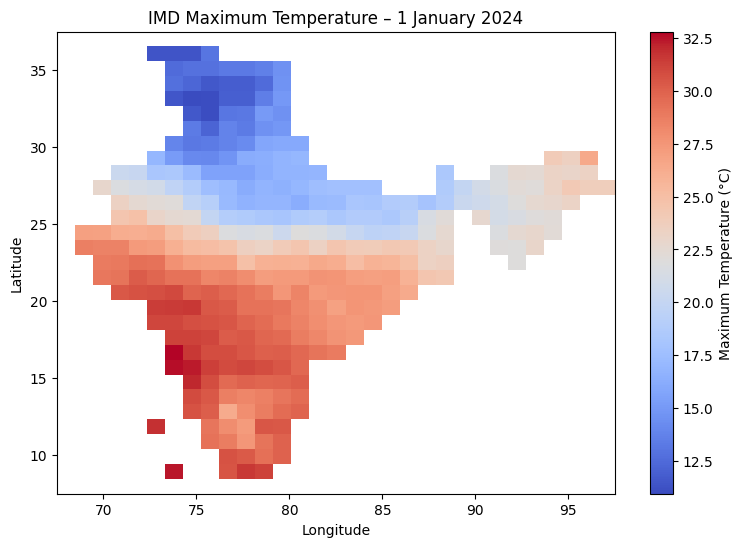

In [13]:
temperature_2024_day1 = temperature_grd[2024][0]

plt.figure(figsize=(9, 6))

plt.imshow(
    temperature_2024_day1,
    extent=[
        reference_lon.min(),
        reference_lon.max(),
        reference_lat.min(),
        reference_lat.max()
    ],
    origin="lower",
    aspect="auto",
    cmap="coolwarm"
)

plt.colorbar(label="Maximum Temperature (°C)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("IMD Maximum Temperature – 1 January 2024")
plt.show()

In [14]:
print("GRD array shape:", temperature_grd[2024].shape)

print("\nLatitude coordinates:")
print(reference_lat)

print("\nLongitude coordinates:")
print(reference_lon)

print("\nFirst grid row corresponds to latitude:",
      reference_lat[0])

print("Last grid row corresponds to latitude:",
      reference_lat[-1])

print("First grid column corresponds to longitude:",
      reference_lon[0])

print("Last grid column corresponds to longitude:",
      reference_lon[-1])

GRD array shape: (366, 31, 31)

Latitude coordinates:
[ 7.5  8.5  9.5 10.5 11.5 12.5 13.5 14.5 15.5 16.5 17.5 18.5 19.5 20.5
 21.5 22.5 23.5 24.5 25.5 26.5 27.5 28.5 29.5 30.5 31.5 32.5 33.5 34.5
 35.5 36.5 37.5]

Longitude coordinates:
[67.5 68.5 69.5 70.5 71.5 72.5 73.5 74.5 75.5 76.5 77.5 78.5 79.5 80.5
 81.5 82.5 83.5 84.5 85.5 86.5 87.5 88.5 89.5 90.5 91.5 92.5 93.5 94.5
 95.5 96.5 97.5]

First grid row corresponds to latitude: 7.5
Last grid row corresponds to latitude: 37.5
First grid column corresponds to longitude: 67.5
Last grid column corresponds to longitude: 97.5


In [15]:
temperature_annual = {}

for year in [2024, 2025]:

    data = temperature_grd[year]

    dates = pd.date_range(
        start=f"{year}-01-01",
        periods=data.shape[0],
        freq="D"
    )

    temperature_annual[year] = xr.DataArray(
        data,
        dims=("time", "lat", "lon"),
        coords={
            "time": dates,
            "lat": reference_lat,
            "lon": reference_lon
        },
        name="maximum_temperature",
        attrs={
            "units": "degrees Celsius",
            "missing_value": "99.9 converted to NaN",
            "source": f"Maxtemp_MaxT_{year}.GRD",
            "date_assignment": "Provisional, based on filename and observation count"
        }
    )

    print(
        year,
        "| Shape:", temperature_annual[year].shape,
        "| Start:", str(dates[0].date()),
        "| End:", str(dates[-1].date()),
        "| Valid:", int(temperature_annual[year].count().values)
    )

2024 | Shape: (366, 31, 31) | Start: 2024-01-01 | End: 2024-12-31 | Valid: 129794
2025 | Shape: (365, 31, 31) | Start: 2025-01-01 | End: 2025-12-31 | Valid: 129552


In [16]:
temperature_stats = []

for file_path in netcdf_files:

    year = int(file_path.stem.split("_")[-1])

    with xr.open_dataset(file_path) as ds:

        values = ds["temperature"].values

        temperature_stats.append({
            "year": year,
            "observations": values.shape[0],
            "valid_values": np.isfinite(values).sum(),
            "minimum": np.nanmin(values),
            "maximum": np.nanmax(values),
            "mean": np.nanmean(values),
            "std": np.nanstd(values)
        })

temperature_stats_df = pd.DataFrame(temperature_stats)

temperature_stats_df.round(3)

,year,observations,valid_values,minimum,maximum,mean,std
0,2000,366,128389,0.620,45.000000,30.669001,5.748
1,2001,365,128749,1.700,46.189999,30.770000,5.421
2,2002,365,128416,-0.080,46.320000,31.125000,5.927
3,2003,365,130443,2.110,46.900002,30.573000,6.232
4,2004,366,129273,0.280,45.700001,30.799000,5.900
5,2005,365,128990,0.220,47.029999,30.634001,6.173
6,2006,365,131334,0.530,45.709999,30.909000,5.519
7,2007,365,129896,1.340,46.080002,30.764000,5.738
8,2008,366,129800,-1.190,44.400002,30.632999,5.690
9,2009,365,127866,5.740,45.889999,31.549999,5.722


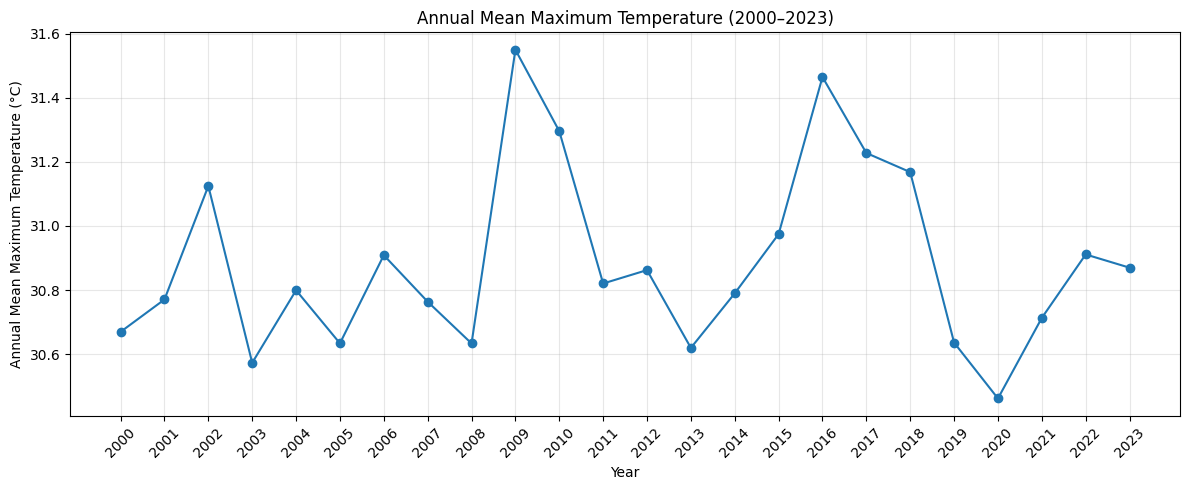

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(
    temperature_stats_df["year"],
    temperature_stats_df["mean"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Annual Mean Maximum Temperature (°C)")
plt.title("Annual Mean Maximum Temperature (2000–2023)")
plt.xticks(temperature_stats_df["year"], rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
common_mask_24 = np.ones((31, 31), dtype=bool)

for file_path in netcdf_files:

    with xr.open_dataset(file_path) as ds:
        values = ds["temperature"].values

        year_mask = np.isfinite(values).all(axis=0)
        common_mask_24 &= year_mask

print("Common valid grid cells:", common_mask_24.sum())
print("Total grid cells:", common_mask_24.size)
print("Common spatial coverage (%):",
      round(common_mask_24.mean() * 100, 2))

Common valid grid cells: 292
Total grid cells: 961
Common spatial coverage (%): 30.39


In [19]:
grd_files = sorted(TEMPERATURE_DIR.glob("*.GRD"))

print("Total GRD files:", len(grd_files))

for file_path in grd_files:
    print(
        file_path.name,
        "|",
        round(file_path.stat().st_size / (1024**2), 3),
        "MB"
    )

Total GRD files: 26
Maxtemp_MaxT_2000.GRD | 1.342 MB
Maxtemp_MaxT_2001.GRD | 1.338 MB
Maxtemp_MaxT_2002.GRD | 1.338 MB
Maxtemp_MaxT_2003.GRD | 1.338 MB
Maxtemp_MaxT_2004.GRD | 1.342 MB
Maxtemp_MaxT_2005.GRD | 1.338 MB
Maxtemp_MaxT_2006.GRD | 1.338 MB
Maxtemp_MaxT_2007.GRD | 1.338 MB
Maxtemp_MaxT_2008.GRD | 1.342 MB
Maxtemp_MaxT_2009.GRD | 1.338 MB
Maxtemp_MaxT_2010.GRD | 1.338 MB
Maxtemp_MaxT_2011.GRD | 1.338 MB
Maxtemp_MaxT_2012.GRD | 1.342 MB
Maxtemp_MaxT_2013.GRD | 1.338 MB
Maxtemp_MaxT_2014.GRD | 1.338 MB
Maxtemp_MaxT_2015.GRD | 1.338 MB
Maxtemp_MaxT_2016.GRD | 1.342 MB
Maxtemp_MaxT_2017.GRD | 1.338 MB
Maxtemp_MaxT_2018.GRD | 1.338 MB
Maxtemp_MaxT_2019.GRD | 1.338 MB
Maxtemp_MaxT_2020.GRD | 1.342 MB
Maxtemp_MaxT_2021.GRD | 1.338 MB
Maxtemp_MaxT_2022.GRD | 1.338 MB
Maxtemp_MaxT_2023.GRD | 1.338 MB
Maxtemp_MaxT_2024.GRD | 1.342 MB
Maxtemp_MaxT_2025.GRD | 1.338 MB


In [20]:
grd_validation = []

for file_path in grd_files:

    year = int(file_path.stem.split("_")[-1])

    expected_days = len(
        pd.date_range(
            f"{year}-01-01",
            f"{year}-12-31",
            freq="D"
        )
    )

    raw = np.fromfile(file_path, dtype="<f4")

    expected_values = expected_days * 31 * 31

    grd_validation.append({
        "year": year,
        "days": expected_days,
        "actual_values": len(raw),
        "expected_values": expected_values,
        "size_match": len(raw) == expected_values,
        "first_value": raw[0],
        "all_finite": np.isfinite(raw).all()
    })

grd_validation_df = pd.DataFrame(grd_validation)

print(grd_validation_df.to_string(index=False))

print("\nAll binary structures valid:",
      grd_validation_df["size_match"].all())

 year  days  actual_values  expected_values  size_match  first_value  all_finite
 2000   366         351726           351726        True    99.900002        True
 2001   365         350765           350765        True    99.900002        True
 2002   365         350765           350765        True    99.900002        True
 2003   365         350765           350765        True    99.900002        True
 2004   366         351726           351726        True    99.900002        True
 2005   365         350765           350765        True    99.900002        True
 2006   365         350765           350765        True    99.900002        True
 2007   365         350765           350765        True    99.900002        True
 2008   366         351726           351726        True    99.900002        True
 2009   365         350765           350765        True    99.900002        True
 2010   365         350765           350765        True    99.900002        True
 2011   365         350765  

In [21]:
grd_missing_stats = []

for file_path in grd_files:

    year = int(file_path.stem.split("_")[-1])

    raw = np.fromfile(file_path, dtype="<f4")

    missing_count = np.sum(np.isclose(raw, 99.9))
    valid_count = len(raw) - missing_count

    valid_values = raw[~np.isclose(raw, 99.9)]

    grd_missing_stats.append({
        "year": year,
        "total_values": len(raw),
        "valid_values": valid_count,
        "missing_values": missing_count,
        "missing_percentage": missing_count / len(raw) * 100,
        "minimum": valid_values.min(),
        "maximum": valid_values.max(),
        "mean": valid_values.mean(),
        "std": valid_values.std()
    })

grd_missing_df = pd.DataFrame(grd_missing_stats)

display(grd_missing_df.round(3))

,year,total_values,valid_values,missing_values,missing_percentage,minimum,maximum,mean,std
0,2000,351726,128389,223337,63.497,0.620,45.000000,30.669001,5.748
1,2001,350765,128749,222016,63.295,1.700,46.189999,30.770000,5.421
2,2002,350765,128416,222349,63.390,-0.080,46.320000,31.125000,5.927
3,2003,350765,130443,220322,62.812,2.110,46.900002,30.573000,6.232
4,2004,351726,129273,222453,63.246,0.280,45.700001,30.799000,5.900
5,2005,350765,128990,221775,63.226,0.220,47.029999,30.634001,6.173
6,2006,350765,131334,219431,62.558,0.530,45.709999,30.909000,5.519
7,2007,350765,129896,220869,62.968,1.340,46.080002,30.764000,5.738
8,2008,351726,129800,221926,63.096,-1.190,44.400002,30.632999,5.690
9,2009,350765,127866,222899,63.547,5.740,45.889999,31.549999,5.722


In [22]:
common_mask = np.ones((31, 31), dtype=bool)

for file_path in grd_files:

    year = int(file_path.stem.split("_")[-1])

    days = len(
        pd.date_range(f"{year}-01-01", f"{year}-12-31")
    )

    raw = np.fromfile(file_path, dtype="<f4")
    data = raw.reshape(days, 31, 31)

    # Convert missing-value marker to NaN
    data = np.where(np.isclose(data, 99.9), np.nan, data)

    year_mask = np.isfinite(data).all(axis=0)
    common_mask &= year_mask

print("Common valid cells:", common_mask.sum())
print("Total grid cells:", common_mask.size)
print("Common spatial coverage:",
      round(common_mask.mean() * 100, 2), "%")

Common valid cells: 292
Total grid cells: 961
Common spatial coverage: 30.39 %


In [23]:
year_complete_count = np.zeros((31, 31), dtype=int)

for file_path in grd_files:

    year = int(file_path.stem.split("_")[-1])

    days = len(
        pd.date_range(f"{year}-01-01", f"{year}-12-31")
    )

    raw = np.fromfile(file_path, dtype="<f4")
    data = raw.reshape(days, 31, 31)

    data = np.where(np.isclose(data, 99.9), np.nan, data)

    year_complete_count += np.isfinite(data).all(axis=0)

unique_counts, frequencies = np.unique(
    year_complete_count, return_counts=True
)

availability_df = pd.DataFrame({
    "complete_years": unique_counts,
    "grid_cells": frequencies
})

display(availability_df)

print("Cells complete in all 26 years:",
      np.sum(year_complete_count == 26))

print("Cells complete in at least 24 years:",
      np.sum(year_complete_count >= 24))

print("Cells complete in at least 20 years:",
      np.sum(year_complete_count >= 20))


,complete_years,grid_cells
0,0,604
1,1,3
2,5,7
3,6,1
4,7,1
5,10,2
6,13,4
7,14,1
8,17,4
9,19,4


Cells complete in all 26 years: 292
Cells complete in at least 24 years: 325
Cells complete in at least 20 years: 330


In [24]:
total_days = 0
valid_days_per_cell = np.zeros((31, 31), dtype=int)

for file_path in grd_files:

    year = int(file_path.stem.split("_")[-1])

    days = len(
        pd.date_range(f"{year}-01-01", f"{year}-12-31")
    )

    raw = np.fromfile(file_path, dtype="<f4")
    data = raw.reshape(days, 31, 31)

    data = np.where(raw.reshape(days, 31, 31) == np.float32(99.9),
                    np.nan, data)

    valid_days_per_cell += np.isfinite(data).sum(axis=0)
    total_days += days

valid_percentage = valid_days_per_cell / total_days * 100

print("Total observations per grid cell:", total_days)
print("Minimum valid-day percentage:", round(valid_percentage.min(), 2))
print("Maximum valid-day percentage:", round(valid_percentage.max(), 2))

thresholds = [0, 50, 75, 90, 95, 99, 100]

for threshold in thresholds:
    count = np.sum(valid_percentage >= threshold)
    print(f"Cells with at least {threshold}% valid days: {count}")

Total observations per grid cell: 9497
Minimum valid-day percentage: 0.0
Maximum valid-day percentage: 100.0
Cells with at least 0% valid days: 961
Cells with at least 50% valid days: 355
Cells with at least 75% valid days: 353
Cells with at least 90% valid days: 349
Cells with at least 95% valid days: 345
Cells with at least 99% valid days: 343
Cells with at least 100% valid days: 292


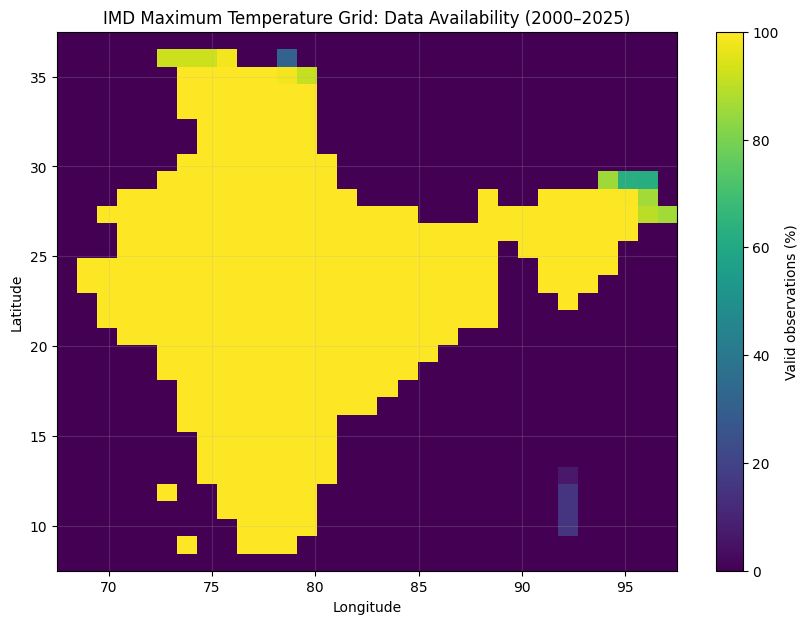

In [25]:
plt.figure(figsize=(10, 7))

plt.imshow(
    valid_percentage,
    origin="lower",
    extent=[67.5, 97.5, 7.5, 37.5],
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100
)

plt.colorbar(label="Valid observations (%)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("IMD Maximum Temperature Grid: Data Availability (2000–2025)")
plt.grid(alpha=0.2)

plt.show()

In [26]:
temperature_lat = np.arange(7.5, 38.0, 1.0)
temperature_lon = np.arange(67.5, 98.0, 1.0)

print("Latitude points:", len(temperature_lat))
print("Longitude points:", len(temperature_lon))

print("Latitude range:",
      temperature_lat.min(), "to", temperature_lat.max())

print("Longitude range:",
      temperature_lon.min(), "to", temperature_lon.max())

print("Latitude spacing:",
      np.unique(np.diff(temperature_lat)))

print("Longitude spacing:",
      np.unique(np.diff(temperature_lon)))

assert len(temperature_lat) == 31
assert len(temperature_lon) == 31

Latitude points: 31
Longitude points: 31
Latitude range: 7.5 to 37.5
Longitude range: 67.5 to 97.5
Latitude spacing: [1.]
Longitude spacing: [1.]


In [27]:
nodes_df = pd.read_csv(SPATIAL_DIR / "grid_nodes.csv")

node_lat = nodes_df["latitude"].to_numpy()
node_lon = nodes_df["longitude"].to_numpy()

inside_temperature_grid = (
    (node_lat >= temperature_lat.min()) &
    (node_lat <= temperature_lat.max()) &
    (node_lon >= temperature_lon.min()) &
    (node_lon <= temperature_lon.max())
)

print("Total research nodes:", len(nodes_df))
print("Nodes inside temperature grid:",
      inside_temperature_grid.sum())
print("Nodes outside temperature grid:",
      (~inside_temperature_grid).sum())

# Grid cells with at least one valid observation
temperature_ever_valid = valid_days_per_cell > 0

print("\nTemperature grid cells with at least one valid observation:",
      temperature_ever_valid.sum())

Total research nodes: 5040
Nodes inside temperature grid: 5036
Nodes outside temperature grid: 4

Temperature grid cells with at least one valid observation: 360


In [28]:
temperature_mapping_candidates = []

for i, (lat, lon) in enumerate(zip(node_lat, node_lon)):

    if not inside_temperature_grid[i]:
        continue

    # Find surrounding grid indices
    r0 = np.searchsorted(temperature_lat, lat, side="right") - 1
    c0 = np.searchsorted(temperature_lon, lon, side="right") - 1

    # Four-corner interpolation requires an upper neighbour
    if r0 < 0 or r0 >= 30 or c0 < 0 or c0 >= 30:
        continue

    r1 = r0 + 1
    c1 = c0 + 1

    # Check whether all four corners have any valid observations
    corners_valid = [
        temperature_ever_valid[r0, c0],
        temperature_ever_valid[r0, c1],
        temperature_ever_valid[r1, c0],
        temperature_ever_valid[r1, c1]
    ]

    if all(corners_valid):
        temperature_mapping_candidates.append(i)

print("Nodes inside temperature grid:",
      inside_temperature_grid.sum())

print("Nodes with four potentially valid corners:",
      len(temperature_mapping_candidates))

print("Nodes without four-corner support:",
      len(nodes_df) - len(temperature_mapping_candidates))

Nodes inside temperature grid: 5036
Nodes with four potentially valid corners: 4476
Nodes without four-corner support: 564


In [29]:
# Identify nodes lying exactly on the grid boundaries
boundary_nodes = (
    (node_lat == temperature_lat.max()) |
    (node_lon == temperature_lon.max())
)

print("Nodes on maximum grid boundaries:",
      boundary_nodes.sum())

print("Boundary nodes inside grid:",
      (boundary_nodes & inside_temperature_grid).sum())

# Separate nodes inside and outside the grid
print("\nNodes inside grid:", inside_temperature_grid.sum())
print("Nodes outside grid:", (~inside_temperature_grid).sum())

# Preliminary support categories
supported_set = set(temperature_mapping_candidates)

inside_supported = sum(
    i in supported_set
    for i in range(len(nodes_df))
    if inside_temperature_grid[i]
)

print("\nInside-grid nodes with four-corner support:",
      inside_supported)

print("Inside-grid nodes without four-corner support:",
      inside_temperature_grid.sum() - inside_supported)

Nodes on maximum grid boundaries: 0
Boundary nodes inside grid: 0

Nodes inside grid: 5036
Nodes outside grid: 4

Inside-grid nodes with four-corner support: 4476
Inside-grid nodes without four-corner support: 560


In [30]:
temperature_mapping = []

for i in temperature_mapping_candidates:

    lat = node_lat[i]
    lon = node_lon[i]

    r0 = np.searchsorted(temperature_lat, lat, side="right") - 1
    c0 = np.searchsorted(temperature_lon, lon, side="right") - 1

    r1 = r0 + 1
    c1 = c0 + 1

    lat0, lat1 = temperature_lat[r0], temperature_lat[r1]
    lon0, lon1 = temperature_lon[c0], temperature_lon[c1]

    # Bilinear interpolation weights
    wy = (lat - lat0) / (lat1 - lat0)
    wx = (lon - lon0) / (lon1 - lon0)

    w00 = (1 - wy) * (1 - wx)
    w01 = (1 - wy) * wx
    w10 = wy * (1 - wx)
    w11 = wy * wx

    temperature_mapping.append({
        "node_index": i,
        "r0": r0,
        "r1": r1,
        "c0": c0,
        "c1": c1,
        "w00": w00,
        "w01": w01,
        "w10": w10,
        "w11": w11
    })

temperature_mapping_df = pd.DataFrame(temperature_mapping)

print("Mapping shape:", temperature_mapping_df.shape)
print("Unique research nodes:",
      temperature_mapping_df["node_index"].nunique())

print("Minimum weight sum:",
      temperature_mapping_df[
          ["w00", "w01", "w10", "w11"]
      ].sum(axis=1).min())

print("Maximum weight sum:",
      temperature_mapping_df[
          ["w00", "w01", "w10", "w11"]
      ].sum(axis=1).max())

display(temperature_mapping_df.head())

Mapping shape: (4476, 9)
Unique research nodes: 4476
Minimum weight sum: 0.9999999999999999
Maximum weight sum: 1.0


,node_index,r0,r1,c0,c1,w00,w01,w10,w11
0,1,1,2,9,10,0.683487,0.083048,0.208171,0.025294
1,2,1,2,9,10,0.633281,0.234834,0.096209,0.035676
2,3,1,2,9,10,0.585590,0.028888,0.367398,0.018124
3,4,1,2,9,10,0.491536,0.149813,0.274874,0.083777
4,5,1,2,9,10,0.299934,0.091415,0.466476,0.142175


In [31]:
temperature_mapping_path = (
    SPATIAL_DIR / "temperature_bilinear_mapping.csv"
)

temperature_mapping_df.to_csv(
    temperature_mapping_path,
    index=False
)

print("Temperature mapping saved to:")
print(temperature_mapping_path)

Temperature mapping saved to:
D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\data\spatial\temperature_bilinear_mapping.csv


In [32]:
year = 2000

file_path = TEMPERATURE_DIR / f"Maxtemp_MaxT_{year}.GRD"

days = len(
    pd.date_range(f"{year}-01-01", f"{year}-12-31")
)

raw = np.fromfile(file_path, dtype="<f4")

temperature_2000 = raw.reshape(days, 31, 31)

# Convert IMD missing-value marker to NaN
temperature_2000 = np.where(
    temperature_2000 == np.float32(99.9),
    np.nan,
    temperature_2000
)

print("Year:", year)
print("Array shape:", temperature_2000.shape)
print("Valid observations:", np.isfinite(temperature_2000).sum())
print("Missing observations:", np.isnan(temperature_2000).sum())
print("Minimum temperature:", np.nanmin(temperature_2000))
print("Maximum temperature:", np.nanmax(temperature_2000))
print("Mean temperature:", np.nanmean(temperature_2000))

Year: 2000
Array shape: (366, 31, 31)
Valid observations: 128389
Missing observations: 223337
Minimum temperature: 0.62
Maximum temperature: 45.0
Mean temperature: 30.66942


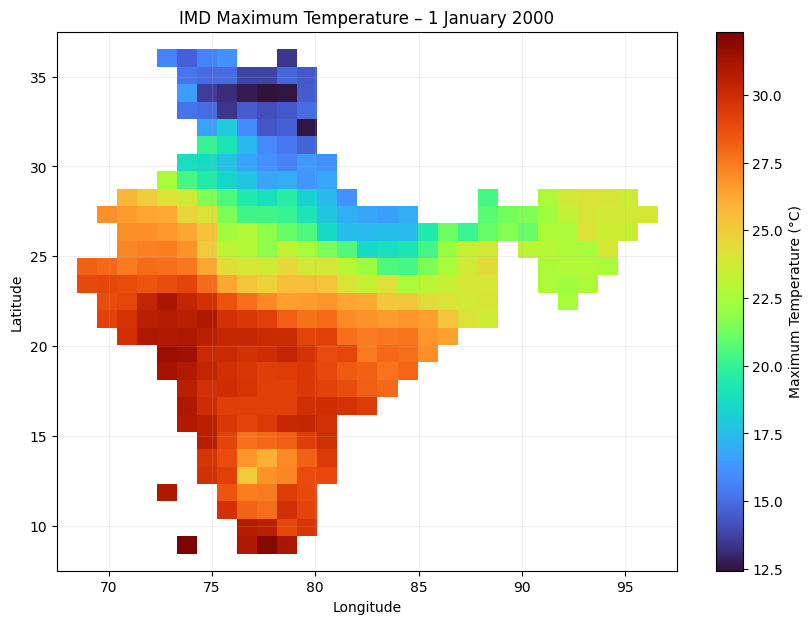

In [33]:
plt.figure(figsize=(10, 7))

plt.imshow(
    temperature_2000[0],
    origin="lower",
    extent=[
        temperature_lon.min(),
        temperature_lon.max(),
        temperature_lat.min(),
        temperature_lat.max()
    ],
    aspect="auto",
    cmap="turbo"
)

plt.colorbar(label="Maximum Temperature (°C)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("IMD Maximum Temperature – 1 January 2000")
plt.grid(alpha=0.2)

plt.show()

In [34]:
temperature_grd = {}
temperature_yearly_stats = []

for file_path in grd_files:

    year = int(file_path.stem.split("_")[-1])

    days = len(
        pd.date_range(f"{year}-01-01", f"{year}-12-31")
    )

    raw = np.fromfile(file_path, dtype="<f4")

    data = raw.reshape(days, 31, 31)

    data[data == np.float32(99.9)] = np.nan

    temperature_grd[year] = data

    temperature_yearly_stats.append({
        "year": year,
        "days": days,
        "valid_values": np.isfinite(data).sum(),
        "missing_values": np.isnan(data).sum(),
        "minimum": np.nanmin(data),
        "maximum": np.nanmax(data),
        "mean": np.nanmean(data)
    })

temperature_yearly_df = pd.DataFrame(temperature_yearly_stats)

print("Years processed:", len(temperature_grd))
print("First year shape:", temperature_grd[2000].shape)
print("Last year shape:", temperature_grd[2025].shape)

display(temperature_yearly_df.round(3))

Years processed: 26
First year shape: (366, 31, 31)
Last year shape: (365, 31, 31)


,year,days,valid_values,missing_values,minimum,maximum,mean
0,2000,366,128389,223337,0.620,45.000000,30.669001
1,2001,365,128749,222016,1.700,46.189999,30.770000
2,2002,365,128416,222349,-0.080,46.320000,31.125000
3,2003,365,130443,220322,2.110,46.900002,30.573000
4,2004,366,129273,222453,0.280,45.700001,30.799000
5,2005,365,128990,221775,0.220,47.029999,30.634001
6,2006,365,131334,219431,0.530,45.709999,30.909000
7,2007,365,129896,220869,1.340,46.080002,30.764000
8,2008,366,129800,221926,-1.190,44.400002,30.632999
9,2009,365,127866,222899,5.740,45.889999,31.549999


In [35]:
spatial_files = list(SPATIAL_DIR.iterdir())

for file_path in spatial_files:
    print(file_path.name)

centroids.shp
grid.shp
grid_nodes.csv
rainfall_bilinear_mapping.csv
rainfall_interpolation_coverage.csv
rainfall_node_coverage.csv
temperature_bilinear_mapping.csv


In [36]:
import geopandas as gpd

for shp_name in ["centroids.shp", "grid.shp"]:

    shp_path = SPATIAL_DIR / shp_name
    gdf = gpd.read_file(shp_path)

    print(f"\n--- {shp_name} ---")
    print("Number of records:", len(gdf))
    print("CRS:", gdf.crs)
    print("Geometry types:", gdf.geom_type.value_counts().to_dict())
    print("Columns:", gdf.columns.tolist())
    print("Bounds:", gdf.total_bounds)

    display(gdf.head())

DataSourceError: Unable to open D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\data\spatial\centroids.shx or D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\data\spatial\centroids.SHX. Set SHAPE_RESTORE_SHX config option to YES to restore or create it.

In [37]:
for shp_name in ["centroids", "grid"]:

    print(f"\n--- {shp_name} ---")

    for extension in [".shp", ".shx", ".dbf", ".prj"]:

        file_path = SPATIAL_DIR / f"{shp_name}{extension}"

        print(
            extension,
            "Exists:", file_path.exists(),
            "Size:", file_path.stat().st_size if file_path.exists() else "N/A"
        )
        


--- centroids ---
.shp Exists: True Size: 141220
.shx Exists: False Size: N/A
.dbf Exists: False Size: N/A
.prj Exists: False Size: N/A

--- grid ---
.shp Exists: True Size: 701736
.shx Exists: False Size: N/A
.dbf Exists: False Size: N/A
.prj Exists: False Size: N/A


In [38]:
print(nodes_df[["latitude", "longitude"]].describe())

print("\nFirst five research nodes:")
display(nodes_df.head())

          latitude    longitude
count  5040.000000  5040.000000
mean     23.364367    79.686979
std       6.119055     6.131353
min       6.880740    68.465904
25%      19.608651    75.483590
50%      23.858651    78.233590
75%      27.108651    82.733590
max      37.002270    97.398749

First five research nodes:


,latitude,longitude
0,8.451258,76.834814
1,8.733465,76.608342
2,8.631885,76.770510
3,8.885523,76.547012
4,8.858651,76.733590


In [39]:
import geopandas as gpd

nodes_gdf = gpd.GeoDataFrame(
    nodes_df.copy(),
    geometry=gpd.points_from_xy(
        nodes_df["longitude"],
        nodes_df["latitude"]
    ),
    crs="EPSG:4326"
)

print("CRS:", nodes_gdf.crs)
print("Total research nodes:", len(nodes_gdf))
print("Geometry types:", nodes_gdf.geom_type.value_counts().to_dict())

display(nodes_gdf.head())

CRS: EPSG:4326
Total research nodes: 5040
Geometry types: {'Point': 5040}


,latitude,longitude,geometry
0,8.451258,76.834814,POINT (76.83481 8.45126)
1,8.733465,76.608342,POINT (76.60834 8.73347)
2,8.631885,76.770510,POINT (76.77051 8.63188)
3,8.885523,76.547012,POINT (76.54701 8.88552)
4,8.858651,76.733590,POINT (76.73359 8.85865)


In [40]:
# Prepare temperature interpolation mapping

mapping = temperature_mapping_df.copy()

node_idx = mapping["node_index"].to_numpy(dtype=int)

r0 = mapping["r0"].to_numpy(dtype=int)
r1 = mapping["r1"].to_numpy(dtype=int)
c0 = mapping["c0"].to_numpy(dtype=int)
c1 = mapping["c1"].to_numpy(dtype=int)

weights = mapping[
    ["w00", "w01", "w10", "w11"]
].to_numpy(dtype=np.float64)

print("Interpolation mapping prepared successfully.")
print("Mapped nodes:", len(node_idx))
print("Unique mapped nodes:", len(np.unique(node_idx)))
print("Total research nodes:", len(nodes_df))
print("Weight array shape:", weights.shape)
print("Minimum weight sum:", weights.sum(axis=1).min())
print("Maximum weight sum:", weights.sum(axis=1).max())

Interpolation mapping prepared successfully.
Mapped nodes: 4476
Unique mapped nodes: 4476
Total research nodes: 5040
Weight array shape: (4476, 4)
Minimum weight sum: 0.9999999999999999
Maximum weight sum: 1.0


In [41]:
# Bilinear interpolation of temperature data for 2000

year = 2000
data = temperature_grd[year]

# Extract four corner values for all mapped nodes
v00 = data[:, r0, c0]
v01 = data[:, r0, c1]
v10 = data[:, r1, c0]
v11 = data[:, r1, c1]

# Require all four corners to be valid on each date
valid = (
    np.isfinite(v00) &
    np.isfinite(v01) &
    np.isfinite(v10) &
    np.isfinite(v11)
)

# Calculate bilinear interpolation
interpolated = (
    weights[:, 0] * v00 +
    weights[:, 1] * v01 +
    weights[:, 2] * v10 +
    weights[:, 3] * v11
)

# Preserve all 5,040 research nodes
temperature_nodes_2000 = np.full(
    (data.shape[0], len(nodes_df)),
    np.nan,
    dtype=np.float32
)

# Assign values only where all four corners are valid
temperature_nodes_2000[:, node_idx] = np.where(
    valid,
    interpolated,
    np.nan
)

print("Year:", year)
print("Original temperature shape:", data.shape)
print("Interpolated temperature shape:", temperature_nodes_2000.shape)
print("Total valid observations:", np.isfinite(temperature_nodes_2000).sum())
print("Total missing observations:", np.isnan(temperature_nodes_2000).sum())
print("Minimum temperature:", np.nanmin(temperature_nodes_2000))
print("Maximum temperature:", np.nanmax(temperature_nodes_2000))
print("Mean temperature:", np.nanmean(temperature_nodes_2000))

Year: 2000
Original temperature shape: (366, 31, 31)
Interpolated temperature shape: (366, 5040)
Total valid observations: 1620001
Total missing observations: 224639
Minimum temperature: 4.0484953
Maximum temperature: 44.90864
Mean temperature: 31.04033


In [42]:
# Validate interpolated temperature data for 2000

daily_valid = np.isfinite(temperature_nodes_2000).sum(axis=1)
daily_missing = np.isnan(temperature_nodes_2000).sum(axis=1)

mapped_valid_nodes = np.isfinite(
    temperature_nodes_2000[:, node_idx]
).sum()

unmapped_idx = np.setdiff1d(
    np.arange(len(nodes_df)),
    node_idx
)

unmapped_valid_nodes = np.isfinite(
    temperature_nodes_2000[:, unmapped_idx]
).sum()

print("Temperature interpolation validation – 2000")
print("-" * 50)

print("Days:", temperature_nodes_2000.shape[0])
print("Minimum valid nodes per day:", daily_valid.min())
print("Maximum valid nodes per day:", daily_valid.max())
print("Average valid nodes per day:", daily_valid.mean())

print("\nMapped-node observations:")
print("Valid:", mapped_valid_nodes)

print("\nUnmapped-node observations:")
print("Valid:", unmapped_valid_nodes)
print("Expected:", 0)

print("\nDaily coverage range:")
print(f"{daily_valid.min() / 5040 * 100:.2f}% to "
      f"{daily_valid.max() / 5040 * 100:.2f}%")

Temperature interpolation validation – 2000
--------------------------------------------------
Days: 366
Minimum valid nodes per day: 4292
Maximum valid nodes per day: 4427
Average valid nodes per day: 4426.232240437159

Mapped-node observations:
Valid: 1620001

Unmapped-node observations:
Valid: 0
Expected: 0

Daily coverage range:
85.16% to 87.84%


In [43]:
# Identify dates with relatively low interpolation coverage

dates_2000 = pd.date_range(
    start="2000-01-01",
    end="2000-12-31",
    freq="D"
)

daily_coverage_df = pd.DataFrame({
    "date": dates_2000,
    "valid_nodes": daily_valid,
    "missing_nodes": daily_missing,
    "coverage_percentage": daily_valid / 5040 * 100
})

print("Daily coverage statistics:")
display(
    daily_coverage_df["coverage_percentage"].describe()
)

print("\n10 dates with lowest coverage:")
display(
    daily_coverage_df.nsmallest(
        10, "coverage_percentage"
    )
)

Daily coverage statistics:


count    366.000000
mean      87.822068
std        0.159473
min       85.158730
25%       87.837302
50%       87.837302
75%       87.837302
max       87.837302
Name: coverage_percentage, dtype: float64


10 dates with lowest coverage:


,date,valid_nodes,missing_nodes,coverage_percentage
151,2000-05-31,4292,748,85.158730
14,2000-01-15,4378,662,86.865079
77,2000-03-18,4378,662,86.865079
41,2000-02-11,4411,629,87.519841
81,2000-03-22,4411,629,87.519841
114,2000-04-24,4411,629,87.519841
0,2000-01-01,4427,613,87.837302
1,2000-01-02,4427,613,87.837302
2,2000-01-03,4427,613,87.837302
3,2000-01-04,4427,613,87.837302


In [44]:
# Inspect source-grid missing values on 31 May 2000

check_date = "2000-05-31"
day_index = pd.Timestamp(check_date).dayofyear - 1

source_day = temperature_grd[2000][day_index]

source_missing = np.isnan(source_day).sum()
source_valid = np.isfinite(source_day).sum()

print("Date:", check_date)
print("Source grid shape:", source_day.shape)
print("Valid source cells:", source_valid)
print("Missing source cells:", source_missing)
print("Total source cells:", source_day.size)

# Count mapped nodes for which all four corners are valid
four_corner_valid = (
    np.isfinite(source_day[r0, c0]) &
    np.isfinite(source_day[r0, c1]) &
    np.isfinite(source_day[r1, c0]) &
    np.isfinite(source_day[r1, c1])
)

print("\nMapped nodes with four valid corners:", four_corner_valid.sum())
print("Mapped nodes without four valid corners:", (~four_corner_valid).sum())

Date: 2000-05-31
Source grid shape: (31, 31)
Valid source cells: 340
Missing source cells: 621
Total source cells: 961

Mapped nodes with four valid corners: 4292
Mapped nodes without four valid corners: 184


In [45]:
# Interpolate temperature data for all years (2000–2025)

temperature_nodes = {}

for year in range(2000, 2026):

    data = temperature_grd[year]

    v00 = data[:, r0, c0]
    v01 = data[:, r0, c1]
    v10 = data[:, r1, c0]
    v11 = data[:, r1, c1]

    valid = (
        np.isfinite(v00) &
        np.isfinite(v01) &
        np.isfinite(v10) &
        np.isfinite(v11)
    )

    interpolated = (
        weights[:, 0] * v00 +
        weights[:, 1] * v01 +
        weights[:, 2] * v10 +
        weights[:, 3] * v11
    )

    output = np.full(
        (data.shape[0], len(nodes_df)),
        np.nan,
        dtype=np.float32
    )

    output[:, node_idx] = np.where(
        valid,
        interpolated,
        np.nan
    )

    temperature_nodes[year] = output

    print(
        f"{year}: Shape={output.shape}, "
        f"Valid={np.isfinite(output).sum():,}, "
        f"Missing={np.isnan(output).sum():,}"
    )

print("\nInterpolation completed for all 26 years.")

2000: Shape=(366, 5040), Valid=1,620,001, Missing=224,639
2001: Shape=(365, 5040), Valid=1,615,271, Missing=224,329
2002: Shape=(365, 5040), Valid=1,612,805, Missing=226,795
2003: Shape=(365, 5040), Valid=1,621,199, Missing=218,401
2004: Shape=(366, 5040), Valid=1,624,532, Missing=220,108
2005: Shape=(365, 5040), Valid=1,620,690, Missing=218,910
2006: Shape=(365, 5040), Valid=1,632,798, Missing=206,802
2007: Shape=(365, 5040), Valid=1,633,031, Missing=206,569
2008: Shape=(366, 5040), Valid=1,633,298, Missing=211,342
2009: Shape=(365, 5040), Valid=1,610,835, Missing=228,765
2010: Shape=(365, 5040), Valid=1,618,353, Missing=221,247
2011: Shape=(365, 5040), Valid=1,628,886, Missing=210,714
2012: Shape=(366, 5040), Valid=1,635,796, Missing=208,844
2013: Shape=(365, 5040), Valid=1,627,584, Missing=212,016
2014: Shape=(365, 5040), Valid=1,632,725, Missing=206,875
2015: Shape=(365, 5040), Valid=1,631,053, Missing=208,547
2016: Shape=(366, 5040), Valid=1,636,851, Missing=207,789
2017: Shape=(3

In [46]:
# Annual validation summary for interpolated temperature data

temperature_interpolation_summary = []

for year, data in temperature_nodes.items():

    valid_count = np.isfinite(data).sum()
    missing_count = np.isnan(data).sum()
    total_count = data.size

    temperature_interpolation_summary.append({
        "year": year,
        "days": data.shape[0],
        "nodes": data.shape[1],
        "valid_observations": valid_count,
        "missing_observations": missing_count,
        "valid_percentage": valid_count / total_count * 100,
        "missing_percentage": missing_count / total_count * 100,
        "minimum_temperature": np.nanmin(data),
        "maximum_temperature": np.nanmax(data),
        "mean_temperature": np.nanmean(data)
    })

temperature_interpolation_summary_df = pd.DataFrame(
    temperature_interpolation_summary
)

display(
    temperature_interpolation_summary_df.round(3)
)

print("\nOverall period: 2000–2025")
print("Total years:", len(temperature_nodes))
print(
    "Total observations:",
    temperature_interpolation_summary_df["valid_observations"].sum()
    + temperature_interpolation_summary_df["missing_observations"].sum()
)

,year,days,nodes,valid_observations,missing_observations,valid_percentage,missing_percentage,minimum_temperature,maximum_temperature,mean_temperature
0,2000,366,5040,1620001,224639,87.822,12.178,4.048,44.909000,31.040001
1,2001,365,5040,1615271,224329,87.806,12.194,4.172,46.164001,31.127001
2,2002,365,5040,1612805,226795,87.672,12.328,3.280,46.231998,31.521000
3,2003,365,5040,1621199,218401,88.128,11.872,4.270,46.862999,30.962000
4,2004,366,5040,1624532,220108,88.068,11.932,1.856,45.686001,31.177999
5,2005,365,5040,1620690,218910,88.100,11.900,1.648,46.964001,31.017000
6,2006,365,5040,1632798,206802,88.758,11.242,3.668,45.629002,31.257000
7,2007,365,5040,1633031,206569,88.771,11.229,3.774,46.011002,31.120001
8,2008,366,5040,1633298,211342,88.543,11.457,1.494,44.354000,30.983999
9,2009,365,5040,1610835,228765,87.564,12.436,6.150,45.786999,31.903000



Overall period: 2000–2025
Total years: 26
Total observations: 47864880


In [47]:
# Save annual interpolated temperature data as NetCDF

TEMPERATURE_NODES_DIR = INTERMEDIATE_DIR / "temperature_nodes"
TEMPERATURE_NODES_DIR.mkdir(parents=True, exist_ok=True)

for year, data in temperature_nodes.items():

    dates = pd.date_range(
        start=f"{year}-01-01",
        end=f"{year}-12-31",
        freq="D"
    )

    ds = xr.Dataset(
        {
            "temperature": (
                ("time", "node"),
                data
            )
        },
        coords={
            "time": dates,
            "node": np.arange(len(nodes_df)),
            "latitude": ("node", nodes_df["latitude"].to_numpy()),
            "longitude": ("node", nodes_df["longitude"].to_numpy())
        },
        attrs={
            "description": "Daily maximum temperature interpolated to research nodes",
            "source": "Original IMD daily maximum temperature GRD files",
            "interpolation": "Bilinear interpolation with four valid corners",
            "missing_value_handling": "IMD 99.9 converted to NaN; no imputation",
            "units": "degree_Celsius"
        }
    )

    ds["temperature"].attrs["units"] = "degree_Celsius"
    ds["temperature"].attrs["long_name"] = "Daily maximum temperature"

    output_file = TEMPERATURE_NODES_DIR / f"temperature_nodes_{year}.nc"

    ds.to_netcdf(output_file)
    ds.close()

    print(f"Saved: {output_file.name}")

print("\nAll 26 annual temperature NetCDF files saved.")

Saved: temperature_nodes_2000.nc
Saved: temperature_nodes_2001.nc
Saved: temperature_nodes_2002.nc
Saved: temperature_nodes_2003.nc
Saved: temperature_nodes_2004.nc
Saved: temperature_nodes_2005.nc
Saved: temperature_nodes_2006.nc
Saved: temperature_nodes_2007.nc
Saved: temperature_nodes_2008.nc
Saved: temperature_nodes_2009.nc
Saved: temperature_nodes_2010.nc
Saved: temperature_nodes_2011.nc
Saved: temperature_nodes_2012.nc
Saved: temperature_nodes_2013.nc
Saved: temperature_nodes_2014.nc
Saved: temperature_nodes_2015.nc
Saved: temperature_nodes_2016.nc
Saved: temperature_nodes_2017.nc
Saved: temperature_nodes_2018.nc
Saved: temperature_nodes_2019.nc
Saved: temperature_nodes_2020.nc
Saved: temperature_nodes_2021.nc
Saved: temperature_nodes_2022.nc
Saved: temperature_nodes_2023.nc
Saved: temperature_nodes_2024.nc
Saved: temperature_nodes_2025.nc

All 26 annual temperature NetCDF files saved.


In [48]:
# Verify all saved annual temperature NetCDF files

temperature_file_list = sorted(
    TEMPERATURE_NODES_DIR.glob("temperature_nodes_*.nc")
)

verification_results = []

for file_path in temperature_file_list:

    year = int(file_path.stem.split("_")[-1])

    with xr.open_dataset(file_path) as ds:

        saved_data = ds["temperature"].values
        expected_dates = pd.date_range(
            f"{year}-01-01",
            f"{year}-12-31",
            freq="D"
        )

        verification_results.append({
            "year": year,
            "shape": saved_data.shape,
            "date_start": pd.Timestamp(ds.time.values[0]).date(),
            "date_end": pd.Timestamp(ds.time.values[-1]).date(),
            "date_count_correct": np.array_equal(
                pd.to_datetime(ds.time.values).normalize(),
                expected_dates
            ),
            "node_count_correct": saved_data.shape[1] == 5040,
            "valid_observations": np.isfinite(saved_data).sum(),
            "missing_observations": np.isnan(saved_data).sum(),
            "data_match": np.allclose(
                saved_data,
                temperature_nodes[year],
                equal_nan=True
            ),
            "coordinates_match": (
                np.allclose(ds["latitude"].values,
                            nodes_df["latitude"].values) and
                np.allclose(ds["longitude"].values,
                            nodes_df["longitude"].values)
            )
        })

temperature_verification_df = pd.DataFrame(
    verification_results
)

display(temperature_verification_df)

print("\nTotal files:", len(temperature_file_list))
print("All date checks passed:",
      temperature_verification_df["date_count_correct"].all())
print("All node checks passed:",
      temperature_verification_df["node_count_correct"].all())
print("All data checks passed:",
      temperature_verification_df["data_match"].all())
print("All coordinate checks passed:",
      temperature_verification_df["coordinates_match"].all())

,year,shape,date_start,date_end,date_count_correct,node_count_correct,valid_observations,missing_observations,data_match,coordinates_match
0,2000,"(366, 5040)",2000-01-01,2000-12-31,True,True,1620001,224639,True,True
1,2001,"(365, 5040)",2001-01-01,2001-12-31,True,True,1615271,224329,True,True
2,2002,"(365, 5040)",2002-01-01,2002-12-31,True,True,1612805,226795,True,True
3,2003,"(365, 5040)",2003-01-01,2003-12-31,True,True,1621199,218401,True,True
4,2004,"(366, 5040)",2004-01-01,2004-12-31,True,True,1624532,220108,True,True
5,2005,"(365, 5040)",2005-01-01,2005-12-31,True,True,1620690,218910,True,True
6,2006,"(365, 5040)",2006-01-01,2006-12-31,True,True,1632798,206802,True,True
7,2007,"(365, 5040)",2007-01-01,2007-12-31,True,True,1633031,206569,True,True
8,2008,"(366, 5040)",2008-01-01,2008-12-31,True,True,1633298,211342,True,True
9,2009,"(365, 5040)",2009-01-01,2009-12-31,True,True,1610835,228765,True,True



Total files: 26
All date checks passed: True
All node checks passed: True
All data checks passed: True
All coordinate checks passed: True


In [49]:
# Prepare rainfall-temperature integration directory

INTEGRATED_DIR = INTERMEDIATE_DIR / "integrated_climate"
INTEGRATED_DIR.mkdir(parents=True, exist_ok=True)

print("Integration directory:", INTEGRATED_DIR)
print("Rainfall files:", len(list(
    (INTERMEDIATE_DIR / "rainfall_nodes").glob("rainfall_nodes_*.nc")
)))
print("Temperature files:", len(list(
    TEMPERATURE_NODES_DIR.glob("temperature_nodes_*.nc")
)))

Integration directory: D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\data\intermediate\integrated_climate
Rainfall files: 26
Temperature files: 26


In [50]:
# Load and inspect rainfall and temperature data for 2000

year = 2000

rainfall_file = (
    INTERMEDIATE_DIR / "rainfall_nodes" /
    f"rainfall_nodes_{year}.nc"
)

temperature_file = (
    TEMPERATURE_NODES_DIR /
    f"temperature_nodes_{year}.nc"
)

rainfall_ds = xr.open_dataset(rainfall_file)
temperature_ds = xr.open_dataset(temperature_file)

print("Rainfall dataset:")
print(rainfall_ds)

print("\nTemperature dataset:")
print(temperature_ds)

# Verify timestamps
rainfall_dates = pd.to_datetime(rainfall_ds.time.values)
temperature_dates = pd.to_datetime(temperature_ds.time.values)

print("\nTimestamp alignment:",
      np.array_equal(rainfall_dates, temperature_dates))

# Verify node coordinates
rainfall_latitudes = rainfall_ds["latitude"].values
rainfall_longitudes = rainfall_ds["longitude"].values

temperature_latitudes = temperature_ds["latitude"].values
temperature_longitudes = temperature_ds["longitude"].values

print("Latitude alignment:",
      np.allclose(rainfall_latitudes, temperature_latitudes))

print("Longitude alignment:",
      np.allclose(rainfall_longitudes, temperature_longitudes))

Rainfall dataset:
<xarray.Dataset> Size: 8MB
Dimensions:    (time: 366, node: 5040)
Coordinates:
  * time       (time) datetime64[ns] 3kB 2000-01-01 2000-01-02 ... 2000-12-31
  * node       (node) int64 40kB 0 1 2 3 4 5 6 ... 5034 5035 5036 5037 5038 5039
    latitude   (node) float64 40kB ...
    longitude  (node) float64 40kB ...
Data variables:
    rainfall   (time, node) float32 7MB ...
Attributes:
    description:    Daily rainfall interpolated to research node coordinates
    source:         RF25_ind2000_rfp25.nc
    interpolation:  Bilinear interpolation using four valid surrounding grid ...

Temperature dataset:
<xarray.Dataset> Size: 8MB
Dimensions:      (time: 366, node: 5040)
Coordinates:
  * time         (time) datetime64[ns] 3kB 2000-01-01 2000-01-02 ... 2000-12-31
  * node         (node) int64 40kB 0 1 2 3 4 5 ... 5034 5035 5036 5037 5038 5039
    latitude     (node) float64 40kB ...
    longitude    (node) float64 40kB ...
Data variables:
    temperature  (time, node) fl

In [51]:
# Examine joint rainfall-temperature availability for 2000

rainfall_data = rainfall_ds["rainfall"].values
temperature_data = temperature_ds["temperature"].values

rainfall_valid = np.isfinite(rainfall_data)
temperature_valid = np.isfinite(temperature_data)

joint_valid = rainfall_valid & temperature_valid

print("Joint data availability – 2000")
print("-" * 45)

print("Total possible observations:", joint_valid.size)

print("Valid rainfall observations:", rainfall_valid.sum())
print("Valid temperature observations:", temperature_valid.sum())

print("Valid joint observations:", joint_valid.sum())
print("Missing joint observations:", (~joint_valid).sum())

print(
    "Joint availability percentage:",
    round(joint_valid.mean() * 100, 2), "%"
)

print("\nNode-day observations:")
print("Rainfall available, temperature missing:",
      (rainfall_valid & ~temperature_valid).sum())

print("Temperature available, rainfall missing:",
      (~rainfall_valid & temperature_valid).sum())

print("Both variables missing:",
      (~rainfall_valid & ~temperature_valid).sum())

Joint data availability – 2000
---------------------------------------------
Total possible observations: 1844640
Valid rainfall observations: 1733376
Valid temperature observations: 1620001
Valid joint observations: 1580840
Missing joint observations: 263800
Joint availability percentage: 85.7 %

Node-day observations:
Rainfall available, temperature missing: 152536
Temperature available, rainfall missing: 39161
Both variables missing: 72103


In [52]:
# Integrate rainfall and temperature for 2000

integrated_ds_2000 = xr.Dataset(
    {
        "rainfall": (
            ("time", "node"),
            rainfall_data.astype(np.float32)
        ),
        "temperature": (
            ("time", "node"),
            temperature_data.astype(np.float32)
        )
    },
    coords={
        "time": rainfall_dates,
        "node": np.arange(len(nodes_df)),
        "latitude": (
            "node",
            nodes_df["latitude"].to_numpy()
        ),
        "longitude": (
            "node",
            nodes_df["longitude"].to_numpy()
        )
    },
    attrs={
        "description": "Daily rainfall and maximum temperature at 5040 research nodes",
        "period": "2000",
        "spatial_nodes": 5040,
        "rainfall_units": "mm/day",
        "temperature_units": "degree_Celsius",
        "missing_value_handling": "Missing values preserved as NaN"
    }
)

integrated_ds_2000["rainfall"].attrs["units"] = "mm/day"
integrated_ds_2000["temperature"].attrs["units"] = "degree_Celsius"

print(integrated_ds_2000)

<xarray.Dataset> Size: 15MB
Dimensions:      (time: 366, node: 5040)
Coordinates:
  * time         (time) datetime64[ns] 3kB 2000-01-01 2000-01-02 ... 2000-12-31
  * node         (node) int64 40kB 0 1 2 3 4 5 ... 5034 5035 5036 5037 5038 5039
    latitude     (node) float64 40kB 8.451 8.733 8.632 ... 29.36 29.33 29.52
    longitude    (node) float64 40kB 76.83 76.61 76.77 ... 95.98 95.75 96.03
Data variables:
    rainfall     (time, node) float32 7MB nan nan 0.0 0.0 ... 0.0 0.0 0.0 nan
    temperature  (time, node) float32 7MB nan 31.02 31.18 30.95 ... nan nan nan
Attributes:
    description:             Daily rainfall and maximum temperature at 5040 r...
    period:                  2000
    spatial_nodes:           5040
    rainfall_units:          mm/day
    temperature_units:       degree_Celsius
    missing_value_handling:  Missing values preserved as NaN


In [53]:
# Validate integrated dataset for 2000

integrated_rainfall = integrated_ds_2000["rainfall"].values
integrated_temperature = integrated_ds_2000["temperature"].values

print("Integrated dataset validation – 2000")
print("-" * 50)

print(
    "Rainfall values unchanged:",
    np.allclose(
        integrated_rainfall,
        rainfall_data,
        equal_nan=True
    )
)

print(
    "Temperature values unchanged:",
    np.allclose(
        integrated_temperature,
        temperature_data,
        equal_nan=True
    )
)

print(
    "Rainfall missing pattern unchanged:",
    np.array_equal(
        np.isnan(integrated_rainfall),
        np.isnan(rainfall_data)
    )
)

print(
    "Temperature missing pattern unchanged:",
    np.array_equal(
        np.isnan(integrated_temperature),
        np.isnan(temperature_data)
    )
)

print(
    "Joint valid observations:",
    (
        np.isfinite(integrated_rainfall) &
        np.isfinite(integrated_temperature)
    ).sum()
)

Integrated dataset validation – 2000
--------------------------------------------------
Rainfall values unchanged: True
Temperature values unchanged: True
Rainfall missing pattern unchanged: True
Temperature missing pattern unchanged: True
Joint valid observations: 1580840


In [54]:
# Integrate rainfall and temperature for all years (2000–2025)

integrated_climate = {}
integration_summary = []

for year in range(2000, 2026):

    rainfall_file = (
        INTERMEDIATE_DIR / "rainfall_nodes" /
        f"rainfall_nodes_{year}.nc"
    )

    temperature_file = (
        TEMPERATURE_NODES_DIR /
        f"temperature_nodes_{year}.nc"
    )

    with xr.open_dataset(rainfall_file) as rainfall_ds:
        rainfall_data = rainfall_ds["rainfall"].values.copy()
        rainfall_dates = pd.to_datetime(rainfall_ds.time.values)
        rainfall_lat = rainfall_ds["latitude"].values.copy()
        rainfall_lon = rainfall_ds["longitude"].values.copy()

    with xr.open_dataset(temperature_file) as temperature_ds:
        temperature_data = temperature_ds["temperature"].values.copy()
        temperature_dates = pd.to_datetime(temperature_ds.time.values)
        temperature_lat = temperature_ds["latitude"].values.copy()
        temperature_lon = temperature_ds["longitude"].values.copy()

    # Verify temporal and spatial alignment
    assert np.array_equal(rainfall_dates, temperature_dates), f"Date mismatch: {year}"
    assert np.allclose(rainfall_lat, temperature_lat), f"Latitude mismatch: {year}"
    assert np.allclose(rainfall_lon, temperature_lon), f"Longitude mismatch: {year}"

    # Create integrated dataset
    ds = xr.Dataset(
        {
            "rainfall": (
                ("time", "node"),
                rainfall_data.astype(np.float32)
            ),
            "temperature": (
                ("time", "node"),
                temperature_data.astype(np.float32)
            )
        },
        coords={
            "time": rainfall_dates,
            "node": np.arange(len(nodes_df)),
            "latitude": ("node", rainfall_lat),
            "longitude": ("node", rainfall_lon)
        },
        attrs={
            "description": "Daily rainfall and maximum temperature at research nodes",
            "period": str(year),
            "spatial_nodes": 5040,
            "missing_value_handling": "Missing values preserved as NaN"
        }
    )

    ds["rainfall"].attrs["units"] = "mm/day"
    ds["temperature"].attrs["units"] = "degree_Celsius"

    integrated_climate[year] = ds

    joint_valid = (
        np.isfinite(rainfall_data) &
        np.isfinite(temperature_data)
    )

    integration_summary.append({
        "year": year,
        "days": len(rainfall_dates),
        "nodes": len(nodes_df),
        "rainfall_valid": np.isfinite(rainfall_data).sum(),
        "temperature_valid": np.isfinite(temperature_data).sum(),
        "joint_valid": joint_valid.sum(),
        "joint_missing": joint_valid.size - joint_valid.sum(),
        "joint_valid_percentage": joint_valid.mean() * 100
    })

    print(
        f"{year}: {len(rainfall_dates)} days, "
        f"{joint_valid.sum():,} joint valid observations"
    )

integration_summary_df = pd.DataFrame(integration_summary)

print("\nIntegration completed for all 26 years.")

2000: 366 days, 1,580,840 joint valid observations
2001: 365 days, 1,576,221 joint valid observations
2002: 365 days, 1,573,762 joint valid observations
2003: 365 days, 1,582,144 joint valid observations
2004: 366 days, 1,585,380 joint valid observations
2005: 365 days, 1,581,646 joint valid observations
2006: 365 days, 1,592,359 joint valid observations
2007: 365 days, 1,592,600 joint valid observations
2008: 366 days, 1,593,045 joint valid observations
2009: 365 days, 1,571,813 joint valid observations
2010: 365 days, 1,579,301 joint valid observations
2011: 365 days, 1,588,490 joint valid observations
2012: 366 days, 1,595,255 joint valid observations
2013: 365 days, 1,587,379 joint valid observations
2014: 365 days, 1,592,246 joint valid observations
2015: 365 days, 1,590,627 joint valid observations
2016: 366 days, 1,596,306 joint valid observations
2017: 365 days, 1,592,055 joint valid observations
2018: 365 days, 1,585,129 joint valid observations
2019: 365 days, 1,588,372 joint

In [55]:
# Review annual rainfall-temperature integration summary

display(
    integration_summary_df.round(3)
)

print("\nOverall integration statistics")
print("-" * 45)

print("Years:", len(integration_summary_df))
print("Total days:", integration_summary_df["days"].sum())
print("Research nodes:", integration_summary_df["nodes"].unique())

print(
    "Total joint valid observations:",
    integration_summary_df["joint_valid"].sum()
)

print(
    "Overall joint availability (%):",
    round(
        integration_summary_df["joint_valid"].sum()
        / (
            integration_summary_df["days"].sum()
            * 5040
        ) * 100,
        2
    )
)

print(
    "Minimum annual joint availability (%):",
    round(integration_summary_df["joint_valid_percentage"].min(), 2)
)

print(
    "Maximum annual joint availability (%):",
    round(integration_summary_df["joint_valid_percentage"].max(), 2)
)

,year,days,nodes,rainfall_valid,temperature_valid,joint_valid,joint_missing,joint_valid_percentage
0,2000,366,5040,1733376,1620001,1580840,263800,85.699
1,2001,365,5040,1728640,1615271,1576221,263379,85.683
2,2002,365,5040,1728640,1612805,1573762,265838,85.549
3,2003,365,5040,1728640,1621199,1582144,257456,86.005
4,2004,366,5040,1733376,1624532,1585380,259260,85.945
5,2005,365,5040,1728640,1620690,1581646,257954,85.978
6,2006,365,5040,1728640,1632798,1592359,247241,86.560
7,2007,365,5040,1728640,1633031,1592600,247000,86.573
8,2008,366,5040,1733376,1633298,1593045,251595,86.361
9,2009,365,5040,1728640,1610835,1571813,267787,85.443



Overall integration statistics
---------------------------------------------
Years: 26
Total days: 9497
Research nodes: [5040]
Total joint valid observations: 41284549
Overall joint availability (%): 86.25
Minimum annual joint availability (%): 85.44
Maximum annual joint availability (%): 86.59


In [56]:
# Save integrated rainfall-temperature datasets for 2000–2025

saved_files = []

for year, ds in integrated_climate.items():

    output_file = (
        INTEGRATED_DIR / f"integrated_climate_{year}.nc"
    )

    ds.to_netcdf(output_file, mode="w")

    saved_files.append(output_file)

    print(f"Saved: {output_file.name}")

print("\nSaving completed.")
print("Total files saved:", len(saved_files))
print("Output directory:", INTEGRATED_DIR)

Saved: integrated_climate_2000.nc
Saved: integrated_climate_2001.nc
Saved: integrated_climate_2002.nc
Saved: integrated_climate_2003.nc
Saved: integrated_climate_2004.nc
Saved: integrated_climate_2005.nc
Saved: integrated_climate_2006.nc
Saved: integrated_climate_2007.nc
Saved: integrated_climate_2008.nc
Saved: integrated_climate_2009.nc
Saved: integrated_climate_2010.nc
Saved: integrated_climate_2011.nc
Saved: integrated_climate_2012.nc
Saved: integrated_climate_2013.nc
Saved: integrated_climate_2014.nc
Saved: integrated_climate_2015.nc
Saved: integrated_climate_2016.nc
Saved: integrated_climate_2017.nc
Saved: integrated_climate_2018.nc
Saved: integrated_climate_2019.nc
Saved: integrated_climate_2020.nc
Saved: integrated_climate_2021.nc
Saved: integrated_climate_2022.nc
Saved: integrated_climate_2023.nc
Saved: integrated_climate_2024.nc
Saved: integrated_climate_2025.nc

Saving completed.
Total files saved: 26
Output directory: D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spa

In [57]:
# Verify all saved integrated climate datasets

verification_results = []

for year in range(2000, 2026):

    file_path = (
        INTEGRATED_DIR / f"integrated_climate_{year}.nc"
    )

    with xr.open_dataset(file_path) as saved_ds:

        expected_days = 366 if pd.Timestamp(year, 12, 31).dayofyear == 366 else 365

        rainfall_saved = saved_ds["rainfall"].values
        temperature_saved = saved_ds["temperature"].values

        rainfall_original = integrated_climate[year]["rainfall"].values
        temperature_original = integrated_climate[year]["temperature"].values

        dates = pd.to_datetime(saved_ds.time.values)

        assert rainfall_saved.shape == (expected_days, 5040)
        assert temperature_saved.shape == (expected_days, 5040)

        assert dates[0] == pd.Timestamp(f"{year}-01-01")
        assert dates[-1] == pd.Timestamp(f"{year}-12-31")

        assert np.allclose(
            rainfall_saved, rainfall_original, equal_nan=True
        )

        assert np.allclose(
            temperature_saved, temperature_original, equal_nan=True
        )

        assert np.array_equal(
            np.isnan(rainfall_saved), np.isnan(rainfall_original)
        )

        assert np.array_equal(
            np.isnan(temperature_saved), np.isnan(temperature_original)
        )

        verification_results.append({
            "year": year,
            "days": len(dates),
            "nodes": saved_ds.sizes["node"],
            "rainfall_match": True,
            "temperature_match": True,
            "missing_patterns_match": True
        })

        print(f"{year}: Verification passed")

verification_df = pd.DataFrame(verification_results)

print("\nFinal verification completed.")
print("Files verified:", len(verification_df))
print("All checks passed:", verification_df["rainfall_match"].all()
      and verification_df["temperature_match"].all()
      and verification_df["missing_patterns_match"].all())

2000: Verification passed
2001: Verification passed
2002: Verification passed
2003: Verification passed
2004: Verification passed
2005: Verification passed
2006: Verification passed
2007: Verification passed
2008: Verification passed
2009: Verification passed
2010: Verification passed
2011: Verification passed
2012: Verification passed
2013: Verification passed
2014: Verification passed
2015: Verification passed
2016: Verification passed
2017: Verification passed
2018: Verification passed
2019: Verification passed
2020: Verification passed
2021: Verification passed
2022: Verification passed
2023: Verification passed
2024: Verification passed
2025: Verification passed

Final verification completed.
Files verified: 26
All checks passed: True
